# 🤖 Step 3 — Machine Learning Model
**Laptop Price Prediction project**

We train **3 algorithms** and compare them using **R² Score, MAE, RMSE and Accuracy**:

| # | Algorithm | Idea in one line |
|---|-----------|------------------|
| 1 | **Decision Tree** | Asks a series of yes/no questions to reach a price |
| 2 | **Random Forest** | Many decision trees vote together |
| 3 | **Gradient Boosting** | Trees are built one after another, each fixing the previous mistakes |

> ⚠️ Run **`01_Data_Cleaning.ipynb`** first so that `cleaned_laptop_data.csv` exists.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

## 2. Load the Cleaned Data

In [2]:
df = pd.read_csv("cleaned_laptop_data.csv")
df.head()

,Company,TypeName,Ram,Weight,Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand,os,Price
0,Lenovo,Notebook,4,1.77,0,0,141.211998,Intel Core i7,0,256,Intel,Windows,42386.39
1,Toshiba,Notebook,4,1.16,0,0,165.632118,Intel Core i5,0,128,Intel,Windows,63392.07
2,HP,Notebook,8,2.50,0,0,127.335675,Intel Core i7,0,256,Nvidia,Windows,55677.60
3,Samsung,Ultrabook,8,1.23,0,0,146.860478,Intel Core i7,0,256,Intel,Windows,91282.48
4,Asus,Gaming,6,3.80,0,1,128.824981,Intel Core i7,0,512,Nvidia,Windows,153715.23


In [3]:
df.shape

(49967, 13)

## 3. Separate Input (X) and Output (y)
* **X** = laptop specifications (what we give to the model)
* **y** = price (what we want to predict)

Prices are very skewed, so we use `log(Price)` as the target. After predicting we convert back with `exp()`.

In [4]:
X = df.drop(columns=["Price"])
y = np.log(df["Price"])

In [5]:
X.head()

,Company,TypeName,Ram,Weight,Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand,os
0,Lenovo,Notebook,4,1.77,0,0,141.211998,Intel Core i7,0,256,Intel,Windows
1,Toshiba,Notebook,4,1.16,0,0,165.632118,Intel Core i5,0,128,Intel,Windows
2,HP,Notebook,8,2.50,0,0,127.335675,Intel Core i7,0,256,Nvidia,Windows
3,Samsung,Ultrabook,8,1.23,0,0,146.860478,Intel Core i7,0,256,Intel,Windows
4,Asus,Gaming,6,3.80,0,1,128.824981,Intel Core i7,0,512,Nvidia,Windows


In [6]:
y.head()

0    10.654583
1    11.057094
2    10.927333
3    11.421714
4    11.942857
Name: Price, dtype: float64

## 4. Train / Test Split
* **80 %** of the data → the model **learns** from it (train)
* **20 %** of the data → we **test** the model on laptops it has never seen

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 39973
Testing rows : 9994


## 5. Preprocessing
Models only understand numbers, so text columns (Company, TypeName, Cpu brand, Gpu brand, os) are converted to numbers with **One-Hot Encoding**. The number columns are kept as they are.

In [8]:
text_columns = ["Company", "TypeName", "Cpu brand", "Gpu brand", "os"]

preprocess = ColumnTransformer(
    transformers=[
        ("encode", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), text_columns)
    ],
    remainder="passthrough"
)

## 6. Helper Function to Measure the Model
This function trains a model, predicts on the test data, and prints the 4 scores.

| Score | Meaning | Better when |
|-------|---------|-------------|
| **R²** | How much of the price variation the model explains | closer to 1 |
| **MAE** | Average error in ₹ | smaller |
| **RMSE** | Like MAE but punishes big mistakes more | smaller |
| **Accuracy %** | `100 − MAPE` (MAPE = average % error) | higher |

All scores are calculated on the **real price in ₹** (after `exp()`).

In [9]:
results = []   # we will store every model's scores here

def train_and_evaluate(name, model):
    # 1) build a pipeline = preprocessing + model
    pipe = Pipeline([
        ("preprocess", preprocess),
        ("model", model)
    ])

    # 2) learn from training data
    pipe.fit(X_train, y_train)

    # 3) predict on unseen test data and convert log(price) back to rupees
    y_pred = np.exp(pipe.predict(X_test))
    y_true = np.exp(y_test)

    # 4) calculate the scores
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = mean_absolute_percentage_error(y_true, y_pred)
    accuracy = (1 - mape) * 100

    # 5) print and store
    print(f"----- {name} -----")
    print(f"R² Score : {r2:.4f}")
    print(f"MAE      : ₹ {mae:,.0f}")
    print(f"RMSE     : ₹ {rmse:,.0f}")
    print(f"Accuracy : {accuracy:.2f} %")

    results.append({"Model": name, "R2 Score": round(r2, 4), "MAE": round(mae),
                    "RMSE": round(rmse), "Accuracy %": round(accuracy, 2)})
    return pipe

## 7. Algorithm 1 — Decision Tree
`max_depth=10` stops the tree from growing too deep (so it does not just memorise the training data).

In [10]:
dt_model = DecisionTreeRegressor(max_depth=10, random_state=42)
dt_pipe = train_and_evaluate("Decision Tree", dt_model)

----- Decision Tree -----
R² Score : 0.8240
MAE      : ₹ 9,853
RMSE     : ₹ 15,740
Accuracy : 83.22 %


## 8. Algorithm 2 — Random Forest
100 trees, each looks at a random part of the data, and their answers are averaged.

In [11]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_pipe = train_and_evaluate("Random Forest", rf_model)

----- Random Forest -----
R² Score : 0.8872
MAE      : ₹ 7,747
RMSE     : ₹ 12,601
Accuracy : 87.00 %


## 9. Algorithm 3 — Gradient Boosting
200 small trees are added one by one, and every new tree corrects the errors of the earlier ones.

In [12]:
gb_model = GradientBoostingRegressor(n_estimators=200, max_depth=4, random_state=42)
gb_pipe = train_and_evaluate("Gradient Boosting", gb_model)

----- Gradient Boosting -----
R² Score : 0.8589
MAE      : ₹ 9,216
RMSE     : ₹ 14,096
Accuracy : 84.41 %


## 10. Compare All 3 Models

In [13]:
results_df = pd.DataFrame(results)
results_df

,Model,R2 Score,MAE,RMSE,Accuracy %
0,Decision Tree,0.8240,9853,15740,83.22
1,Random Forest,0.8872,7747,12601,87.00
2,Gradient Boosting,0.8589,9216,14096,84.41


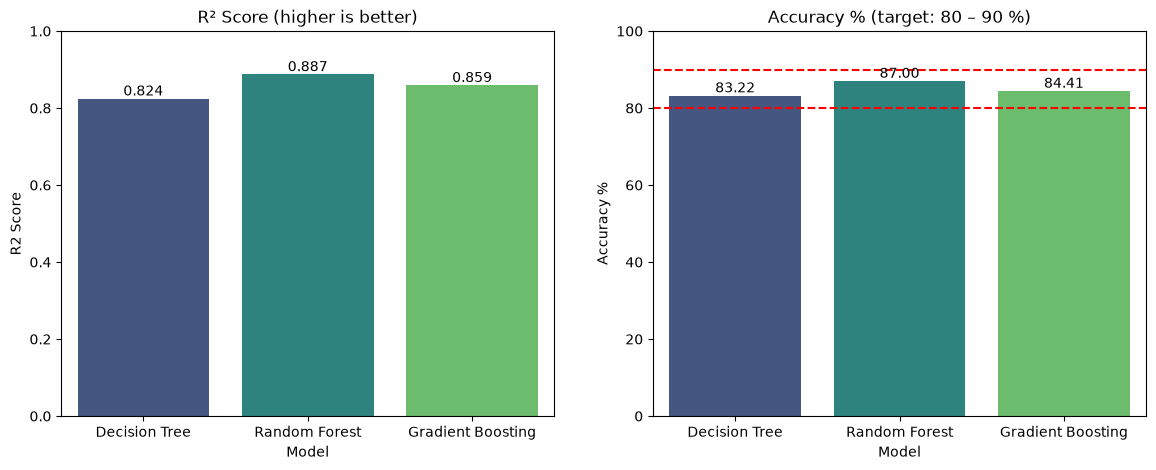

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=results_df, x="Model", y="R2 Score", hue="Model", palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("R² Score (higher is better)")
ax[0].set_ylim(0, 1)
for bar in ax[0].containers:
    ax[0].bar_label(bar, fmt="%.3f")

sns.barplot(data=results_df, x="Model", y="Accuracy %", hue="Model", palette="viridis", legend=False, ax=ax[1])
ax[1].set_title("Accuracy % (target: 80 – 90 %)")
ax[1].set_ylim(0, 100)
ax[1].axhline(80, color="red", linestyle="--")
ax[1].axhline(90, color="red", linestyle="--")
for bar in ax[1].containers:
    ax[1].bar_label(bar, fmt="%.2f")

plt.show()

In [15]:
# Is every accuracy between 80 % and 90 % ?
for _, row in results_df.iterrows():
    ok = 80 <= row["Accuracy %"] <= 90
    print(f"{row['Model']:<18} {row['Accuracy %']:>6.2f} %   ->", "✅ within 80-90 %" if ok else "❌ outside range")

Decision Tree       83.22 %   -> ✅ within 80-90 %
Random Forest       87.00 %   -> ✅ within 80-90 %
Gradient Boosting   84.41 %   -> ✅ within 80-90 %


## 11. Check Real Predictions
Let us compare actual and predicted prices of 8 test laptops using the Random Forest.

In [16]:
sample_X = X_test.head(8)
actual = np.exp(y_test.head(8)).round()
predicted = np.exp(rf_pipe.predict(sample_X)).round()

compare = sample_X[["Company", "TypeName", "Ram", "SSD"]].copy()
compare["Actual Price"] = actual.values
compare["Predicted Price"] = predicted
compare["Error"] = (compare["Predicted Price"] - compare["Actual Price"]).abs()
compare

,Company,TypeName,Ram,SSD,Actual Price,Predicted Price,Error
12338,HP,Notebook,6,0,30525.0,28528.0,1997.0
22390,Lenovo,Notebook,8,256,55971.0,69750.0,13779.0
46345,MSI,Gaming,6,256,103378.0,88380.0,14998.0
39768,Dell,Notebook,24,0,46704.0,40720.0,5984.0
23801,Toshiba,Ultrabook,8,256,88115.0,80581.0,7534.0
2574,Dell,Gaming,8,0,46981.0,52783.0,5802.0
49338,Lenovo,Notebook,4,0,24935.0,27812.0,2877.0
725,Dell,2 in 1 Convertible,8,256,43844.0,53110.0,9266.0


## 12. Choose the Best Model and Save It
We pick the model with the highest **R² Score**, then save:
* `pipe.pkl` → the trained model (used by `LAPP.py`)
* `df.pkl` → the cleaned data (used by `LAPP.py` to fill the drop-down lists)

In [17]:
pipes = {
    "Decision Tree": dt_pipe,
    "Random Forest": rf_pipe,
    "Gradient Boosting": gb_pipe
}

best_name = results_df.sort_values("R2 Score", ascending=False).iloc[0]["Model"]
best_pipe = pipes[best_name]

print("🏆 Best model:", best_name)

🏆 Best model: Random Forest


In [18]:
pickle.dump(best_pipe, open("pipe.pkl", "wb"))
pickle.dump(df, open("df.pkl", "wb"))

print("✅ pipe.pkl and df.pkl saved!")
print("Now run the app with:  streamlit run LAPP.py")

✅ pipe.pkl and df.pkl saved!
Now run the app with:  streamlit run LAPP.py
